# Voltage rule with a gain linear in fish length, $g(L) = \alpha + \beta L$ (2- and 3-fish controls, newest tables)

**Predictions used** (no new solves): `eod_assignment_control_groups.py`, `<res>/conductivities/my_model_shape_synch_fix_newest.csv`, every EOD
of the `*_synch_fix_newest.csv` tables at its own frame, ZEUS masks, BEM conductivities, sink at the tail tip. Per EOD: recorded peak
pattern $r$ (V; each pair demeaned, at the sample where |V| peaks over the pairs) and each fish's unit-current pattern; the model is
used × −1, $m_f$, as in the shape-only run.

**Fit.** The predicted voltage of fish f is $\hat r_f = (\alpha + \beta L_f)\, m_f$, no normalisation:
$$\min_{\alpha,\beta} \sum_{i}\sum_{p} \big(r_{i,p} - (\alpha + \beta L_{e})\, m_{i,e,p}\big)^2$$
over EODs of the true emitter e (2-fish: fish 1; 3-fish: fish 0), pooled over both recordings, plain least squares in volts (linear in
α and β). $L_f$ = fish length from `fish_lengths_<n>fish.json` (straight clean masks).

**Caution.** Only two fish ever emit (2-fish fish 1, 16.5 cm; 3-fish fish 0, 11.9 cm), and they are in different recordings. So
α and β are set by the two recordings' gains: the line passes (in least squares) through one gain per recording, and the slope says
as much about the two set-ups as about fish size. What the length term changes is the predicted size of the **silent** fish.

**Held out.** Each recording is split into blocks of 2,000 video frames, alternating between two folds; α and β are fitted on the
**clean good** emitter EODs of one fold (both recordings) and applied to the other fold, so every EOD gets a prediction from a fit
that did not see it.

**Rules compared** (a fish without a mask midline cannot be picked; an EOD with no pick counts as wrong):
- **shape only** (the run's pick): $m_f$ and $r$ each scaled to max |v| = 1, L2;
- **voltage, one gain**: $\hat r_f = g\, m_f$, one $g$ for every fish of both recordings (least squares on the same training EODs);
- **voltage, one gain per recording**: $\hat r_f = g_{rec}\, m_f$, one $g$ per recording, same for all its fish (the fair baseline:
  in each recording it gives the emitter the same size as $g(L)$ does, so the two differ only in the silent fish's size);
- **voltage, $g(L) = \alpha + \beta L$**: pick the fish with the smallest $\lVert r - \hat r_f\rVert$ (volts).

**L2 of the true emitter**, on the same scale for all rules: $\lVert r - \hat r_e\rVert / \max|r|$ (shape only: the run's $d_e$, which
equals this with $\hat r_e$ = the model scaled to the recorded peak). Groups: all EODs and **clean good** (newest QC: mask QC, Denis'
SLEAP-good rule and the 0.8 × median mask-length limit).

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
%matplotlib inline

OUT = 'results/baseline_g0/voltage_linear_length_newest'; os.makedirs(OUT, exist_ok=True)
PX_CM = 912 / 60; BLOCK = 2000
REC = {'2-fish': dict(res='results/eod_ground_truth', emitter=1, lengths='results/eod_ground_truth/fish_lengths_2fish.json', label='2-fish (2024-02-13)'),
       '3-fish': dict(res='results/eod_ground_truth_3fish', emitter=0, lengths='results/eod_ground_truth_3fish/fish_lengths_3fish.json', label='3-fish (2024-10-15)')}
SH, V0, VR, VL = 'shape only', 'voltage, one gain', 'voltage, one gain per recording', 'voltage, g(L) = α + βL'
PIPE_COL = {SH: '#C9C9C3', V0: '#85857F', VR: '#3a3a36', VL: '#1F5FBF'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z**2 / (2 * n)) / (1 + z**2 / n); hw = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (c - hw), 100 * (c + hw)

D = {}
for name, c in REC.items():
    d = pd.read_csv(f"{c['res']}/conductivities/my_model_shape_synch_fix_newest.csv")
    cg = pd.read_csv(f"{c['res']}/eod_clean_good_synch_fix_newest.csv"); assert (cg.Frame.to_numpy() == d.Frame.to_numpy()).all()
    fish = sorted(int(x[1:-5]) for x in d.columns if x.startswith('u') and x.endswith('_norm'))
    L = json.load(open(c['lengths']))['fish']; Lcm = np.array([L[str(f)]['L_px'] / PX_CM for f in fish])
    r = d[[f'r_raw_p{p}' for p in range(1, 11)]].to_numpy()
    m = np.stack([-d[[f'u{f}_raw_p{p}' for p in range(1, 11)]].to_numpy() for f in fish], axis=1)   # (n, F, 10), model x -1
    ok = np.stack([d[f'fish_ok_{f}'].to_numpy(bool) for f in fish], axis=1) & np.isfinite(m).all(2)
    D[name] = dict(r=r, m=m, ok=ok, L=Lcm, e=c['emitter'], clean=cg.clean_good.to_numpy(bool), fold=(d.Frame.to_numpy() // BLOCK) % 2,
                   shape_pick=d.pick.to_numpy(), d_shape=d[f"d{c['emitter']}"].to_numpy(), frame=d.Frame.to_numpy(), n=len(d))
    print(f"{c['label']}: {len(d)} EODs, clean good {D[name]['clean'].sum()}; fish lengths (cm) {dict(zip(fish, Lcm.round(2)))}; emitter fish {c['emitter']}")

2-fish (2024-02-13): 18801 EODs, clean good 3536; fish lengths (cm) {0: np.float64(11.08), 1: np.float64(16.49)}; emitter fish 1
3-fish (2024-10-15): 19796 EODs, clean good 6764; fish lengths (cm) {0: np.float64(11.89), 1: np.float64(16.55), 2: np.float64(14.04)}; emitter fish 0


## Fit

In [2]:
def train_rows(name, fold=None):
    x = D[name]; k = x['clean'] & x['ok'][:, x['e']]
    if fold is not None: k &= x['fold'] == fold
    return x['r'][k], x['m'][k, x['e']], x['L'][x['e']]

def fit_lin(fold=None):
    '''alpha, beta of r ~ (alpha + beta L_e) m_e, pooled over both recordings (2 x 2 normal equations).'''
    A = np.zeros((2, 2)); b = np.zeros(2)
    for name in D:
        R, M, Le = train_rows(name, fold); X = np.stack([M.ravel(), Le * M.ravel()], 1)
        A += X.T @ X; b += X.T @ R.ravel()
    return np.linalg.solve(A, b)

def fit_one(fold=None, names=None):
    num = den = 0.0
    for name in (names or D):
        R, M, _ = train_rows(name, fold); num += (R * M).sum(); den += (M * M).sum()
    return num / den

PAR = {f: dict(alpha_beta=fit_lin(1 - f), g=fit_one(1 - f), g_rec={nm: fit_one(1 - f, [nm]) for nm in D}) for f in (0, 1)}                # parameters applied to fold f
ab_all = fit_lin(); g_all = fit_one(); g_rec = {name: fit_one(names=[name]) for name in D}
P = pd.DataFrame([dict(fit='all clean-good emitter EODs', alpha=ab_all[0], beta=ab_all[1], one_gain=g_all)] +
                 [dict(fit=f'applied to fold {f} (fitted on fold {1 - f})', alpha=PAR[f]['alpha_beta'][0], beta=PAR[f]['alpha_beta'][1], one_gain=PAR[f]['g']) for f in (0, 1)])
P.to_csv(f'{OUT}/fitted_parameters.csv', index=False); display(P.round(4))
print('one gain per recording (clean-good emitter EODs):', {k: round(v, 4) for k, v in g_rec.items()})
for name in D:
    x = D[name]; print(f"{name}: g(L) per fish (all-data fit): " + ', '.join(f'fish {f} ({L:.1f} cm) {ab_all[0] + ab_all[1] * L:.3f}' for f, L in enumerate(x['L'])))

,fit,alpha,beta,one_gain
0,all clean-good emitter EODs,2.4327,-0.1154,0.6388
1,applied to fold 0 (fitted on fold 1),2.4367,-0.1170,0.5888
2,applied to fold 1 (fitted on fold 0),2.3962,-0.1115,0.6898


one gain per recording (clean-good emitter EODs): {'2-fish': np.float64(0.5302), '3-fish': np.float64(1.0604)}
2-fish: g(L) per fish (all-data fit): fish 0 (11.1 cm) 1.155, fish 1 (16.5 cm) 0.530
3-fish: g(L) per fish (all-data fit): fish 0 (11.9 cm) 1.060, fish 1 (16.5 cm) 0.524, fish 2 (14.0 cm) 0.813


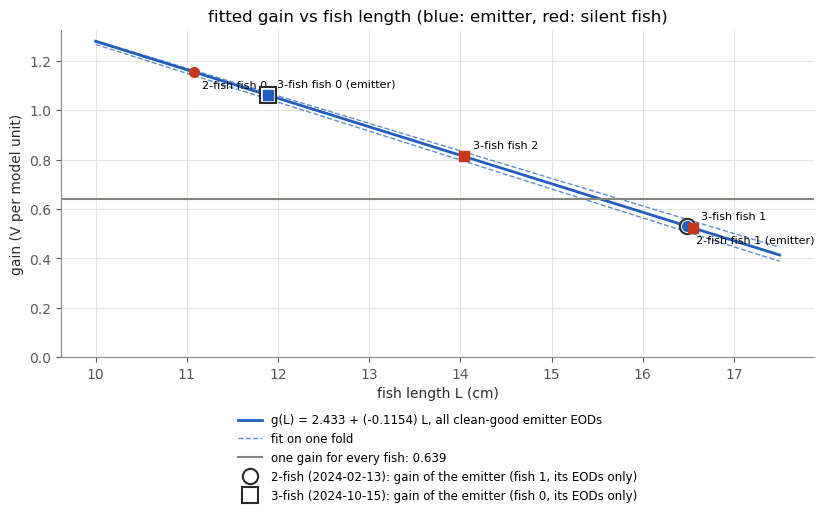

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
xs = np.linspace(10, 17.5, 50)
ax.plot(xs, ab_all[0] + ab_all[1] * xs, color='#1F5FBF', lw=2, label=f'g(L) = {ab_all[0]:.3f} + ({ab_all[1]:.4f}) L, all clean-good emitter EODs')
for f in (0, 1):
    a_, b_ = PAR[f]['alpha_beta']; ax.plot(xs, a_ + b_ * xs, color='#1F5FBF', lw=1, ls='--', alpha=0.7, label='fit on one fold' if f == 0 else None)
ax.axhline(g_all, color='#85857F', lw=1.5, label=f'one gain for every fish: {g_all:.3f}')
mk = {'2-fish': 'o', '3-fish': 's'}
for name, x in D.items():
    Le = x['L'][x['e']]; ax.plot(Le, g_rec[name], mk[name], ms=11, color='#2b2b2b', mfc='white', mew=1.5, zorder=4,
                                 label=f'{REC[name]["label"]}: gain of the emitter (fish {x["e"]}, its EODs only)')
    for f, L in enumerate(x['L']):
        y = ab_all[0] + ab_all[1] * L
        ax.plot(L, y, mk[name], ms=7, color='#1F5FBF' if f == x['e'] else '#C8361E', zorder=5)
        ax.annotate(f"{name} fish {f}{' (emitter)' if f == x['e'] else ''}", (L, y), xytext=(6, -12 if name == '2-fish' else 6),
                    textcoords='offset points', fontsize=8)
ax.set(xlabel='fish length L (cm)', ylabel='gain (V per model unit)', ylim=(0, None), title='fitted gain vs fish length (blue: emitter, red: silent fish)')
ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); fig.savefig(f'{OUT}/gain_vs_length.png', dpi=110, bbox_inches='tight'); plt.show()

## Assignment and L2 (held out by fold)

In [4]:
rows, L2rows = [], []
for name, x in D.items():
    n = x['n']; pick = {SH: x['shape_pick']}; err = {SH: x['d_shape']}
    for pl in (V0, VR, VL):
        p_ = np.full(n, -1); e_ = np.full(n, np.nan)
        for f in (0, 1):
            k = x['fold'] == f; a_, b_ = PAR[f]['alpha_beta']
            gain = (np.full(len(x['L']), PAR[f]['g']) if pl == V0 else np.full(len(x['L']), PAR[f]['g_rec'][name]) if pl == VR
                    else a_ + b_ * x['L'])
            dist = np.linalg.norm(x['r'][k, None] - gain[None, :, None] * x['m'][k], axis=2)
            dist = np.where(x['ok'][k], dist, np.inf)
            p_[k] = np.where(np.isfinite(dist.min(1)), dist.argmin(1), -1)
            e_[k] = dist[:, x['e']] / np.abs(x['r'][k]).max(1)
        pick[pl] = p_; err[pl] = np.where(np.isfinite(e_), e_, np.nan)
    x['pick'] = pick; x['err'] = err
    for grp, msk in (('all EODs', np.ones(n, bool)), ('clean good', x['clean'])):
        for pl in PIPE_COL:
            k_ = int((pick[pl][msk] == x['e']).sum()); nn = int(msk.sum()); lo, hi = wilson(k_, nn)
            rows.append(dict(recording=REC[name]['label'], EODs=grp, rule=pl, n=nn, wrong=nn - k_, pct_correct=100 * k_ / nn, ci_lo=lo, ci_hi=hi))
            v = err[pl][msk]; v = v[np.isfinite(v)]
            L2rows.append(dict(recording=REC[name]['label'], EODs=grp, rule=pl, n=len(v), median=np.median(v), q25=np.percentile(v, 25), q75=np.percentile(v, 75)))
ACC = pd.DataFrame(rows); L2 = pd.DataFrame(L2rows)
ACC.to_csv(f'{OUT}/accuracy.csv', index=False); L2.to_csv(f'{OUT}/l2_true_emitter.csv', index=False)
display(ACC.pivot_table(index=['recording', 'EODs'], columns='rule', values='pct_correct', sort=False)[list(PIPE_COL)].round(2))
display(L2.pivot_table(index=['recording', 'EODs'], columns='rule', values='median', sort=False)[list(PIPE_COL)].round(3))
for name, x in D.items():
    for grp, msk in (('all EODs', np.ones(x['n'], bool)), ('clean good', x['clean'])):
        a_ = x['pick'][SH][msk] == x['e']; b_ = x['pick'][VL][msk] == x['e']
        c_ = x['pick'][VR][msk] == x['e']
        print(f"{name}, {grp}: only shape right {(a_ & ~b_).sum()}, only g(L) right {(~a_ & b_).sum()}, both wrong {(~a_ & ~b_).sum()}; "
              f"g(L) vs one gain per recording: only g(L) {(b_ & ~c_).sum()}, only per-recording {(~b_ & c_).sum()}")

rule                            shape only  voltage, one gain  \
recording           EODs                                        
2-fish (2024-02-13) all EODs         96.91              95.63   
                    clean good       99.15              98.16   
3-fish (2024-10-15) all EODs         89.78              89.52   
                    clean good       98.09              97.87   

rule                            voltage, one gain per recording  \
recording           EODs                                          
2-fish (2024-02-13) all EODs                              97.10   
                    clean good                            99.24   
3-fish (2024-10-15) all EODs                              90.85   
                    clean good                            98.76   

rule                            voltage, g(L) = α + βL  
recording           EODs                                
2-fish (2024-02-13) all EODs                     98.31  
                    clean good                   99.32  
3-fish (2024-10-15) all EODs                     88.85  
                    clean good                   98.17

rule                            shape only  voltage, one gain  \
recording           EODs                                        
2-fish (2024-02-13) all EODs         0.306              0.580   
                    clean good       0.331              0.594   
3-fish (2024-10-15) all EODs         0.434              0.740   
                    clean good       0.412              0.691   

rule                            voltage, one gain per recording  \
recording           EODs                                          
2-fish (2024-02-13) all EODs                              0.458   
                    clean good                            0.474   
3-fish (2024-10-15) all EODs                              0.547   
                    clean good                            0.499   

rule                            voltage, g(L) = α + βL  
recording           EODs                                
2-fish (2024-02-13) all EODs                     0.458  
                    clean good                   0.474  
3-fish (2024-10-15) all EODs                     0.547  
                    clean good                   0.499

2-fish, all EODs: only shape right 93, only g(L) right 356, both wrong 225; g(L) vs one gain per recording: only g(L) 309, only per-recording 82
2-fish, clean good: only shape right 18, only g(L) right 24, both wrong 6; g(L) vs one gain per recording: only g(L) 18, only per-recording 15
3-fish, all EODs: only shape right 384, only g(L) right 201, both wrong 1823; g(L) vs one gain per recording: only g(L) 52, only per-recording 447
3-fish, clean good: only shape right 26, only g(L) right 31, both wrong 98; g(L) vs one gain per recording: only g(L) 8, only per-recording 48


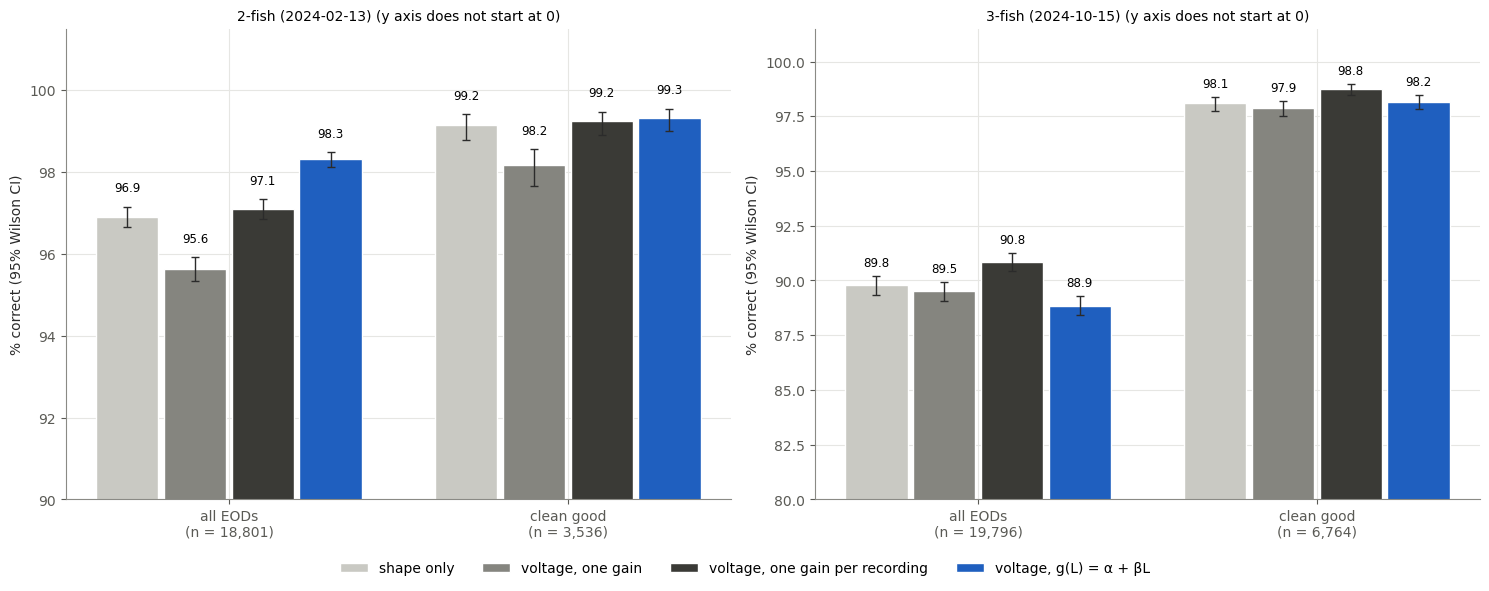

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6))
grps = ['all EODs', 'clean good']; w = 0.2
for ax, (name, c) in zip(axs, REC.items()):
    t = ACC[ACC.recording == c['label']]
    for g, grp in enumerate(grps):
        for i, pl in enumerate(PIPE_COL):
            s = t[(t.EODs == grp) & (t.rule == pl)].iloc[0]; xx = g + (i - 1.5) * w
            ax.bar(xx, s.pct_correct, w * 0.92, color=PIPE_COL[pl], edgecolor='white', label=pl if g == 0 else None)
            ax.errorbar(xx, s.pct_correct, [[s.pct_correct - s.ci_lo], [s.ci_hi - s.pct_correct]], color='#2b2b2b', capsize=3, lw=1)
            ax.text(xx, s.ci_hi + 0.3, f'{s.pct_correct:.1f}', ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks(range(len(grps)), [f"{g_}\n(n = {t[t.EODs == g_].n.iloc[0]:,})" for g_ in grps])
    ax.set(ylim=(np.floor(t.ci_lo.min() / 5) * 5 - 5, 101.5), ylabel='% correct (95% Wilson CI)')
    ax.set_title(f"{c['label']} (y axis does not start at 0)", fontsize=10)
h_, l_ = axs[0].get_legend_handles_labels()
plt.tight_layout(); fig.legend(h_, l_, frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=4)
fig.savefig(f'{OUT}/accuracy.png', dpi=110, bbox_inches='tight'); plt.show()

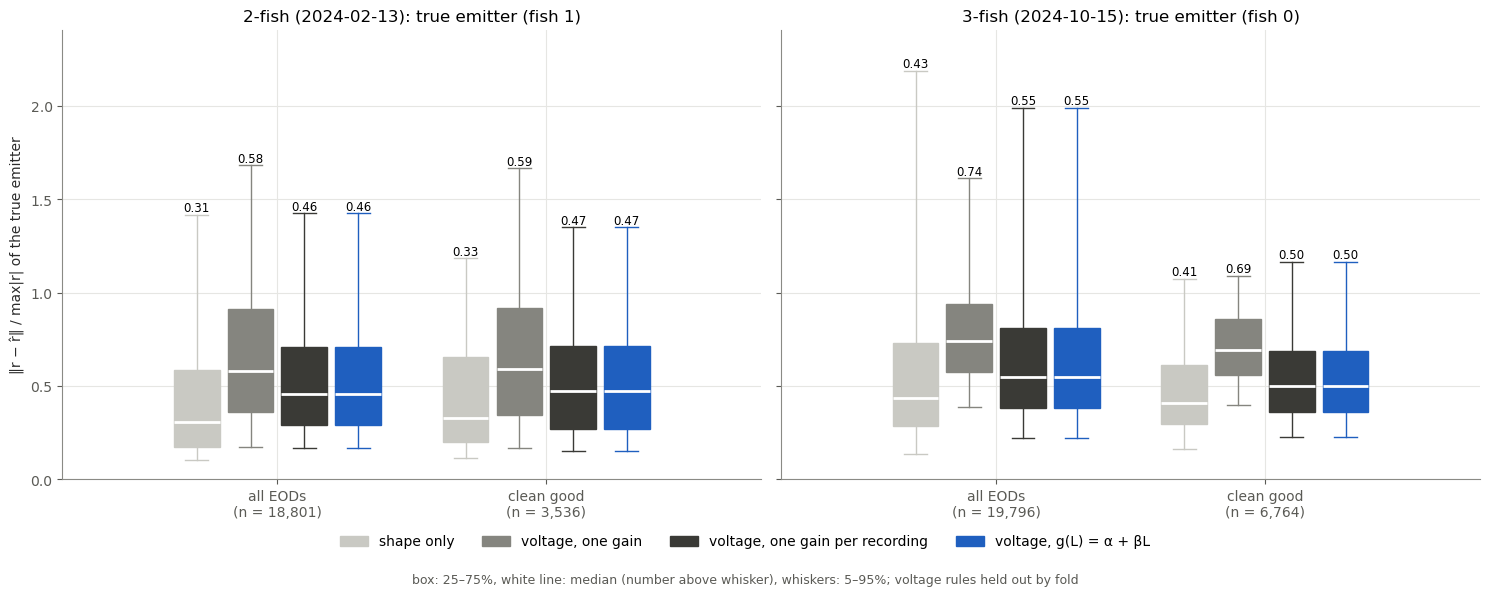

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
TOP = max(np.nanpercentile(x['err'][pl][np.isfinite(x['err'][pl])], 95) for x in D.values() for pl in PIPE_COL) * 1.1
for ax, (name, x) in zip(axs, D.items()):
    for g, (grp, msk) in enumerate((('all EODs', np.ones(x['n'], bool)), ('clean good', x['clean']))):
        for i, pl in enumerate(PIPE_COL):
            v = x['err'][pl][msk]; v = v[np.isfinite(v)]; pos = g + (i - 1.5) * w
            ax.boxplot([v], positions=[pos], widths=w * 0.85, whis=(5, 95), showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=PIPE_COL[pl], edgecolor=PIPE_COL[pl]), medianprops=dict(color='white', lw=2),
                       whiskerprops=dict(color=PIPE_COL[pl]), capprops=dict(color=PIPE_COL[pl]))
            ax.text(pos, np.percentile(v, 95), f'{np.median(v):.2f}', ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks([0, 1], [f'all EODs\n(n = {x["n"]:,})', f'clean good\n(n = {x["clean"].sum():,})'])
    ax.set(ylim=(0, TOP), title=f"{REC[name]['label']}: true emitter (fish {x['e']})")
axs[0].set_ylabel('‖r − r̂‖ / max|r| of the true emitter')
fig.legend(handles=[Patch(color=c_, label=pl) for pl, c_ in PIPE_COL.items()], loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.05))
fig.text(0.5, -0.09, 'box: 25–75%, white line: median (number above whisker), whiskers: 5–95%; voltage rules held out by fold', ha='center', fontsize=9, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/l2_true_emitter.png', dpi=110, bbox_inches='tight'); plt.show()